# ***Exploratory dataset analysis***

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.features import RAW_PATH

In [2]:
df = pd.read_csv(RAW_PATH)

In [3]:
print('Shape:', df.shape)
print()



Shape: (2514, 15)



In [4]:
print('Null counts per column:')
print(df.isnull().sum())
print()
print('Total nulls:', df.isnull().sum().sum())
print('Rows with any null:', df.isnull().any(axis=1).sum())

Null counts per column:
review_id              0
user_id                0
app_name               0
app_category           0
review_text           59
review_language        0
rating                37
review_date            0
verified_purchase      0
device_type            0
num_helpful_votes      0
user_age               0
user_country          41
user_gender          587
app_version           30
dtype: int64

Total nulls: 754
Rows with any null: 713


In [5]:
print()
print('Null % per column:')
print((df.isnull().mean() * 100).round(2))


Null % per column:
review_id             0.00
user_id               0.00
app_name              0.00
app_category          0.00
review_text           2.35
review_language       0.00
rating                1.47
review_date           0.00
verified_purchase     0.00
device_type           0.00
num_helpful_votes     0.00
user_age              0.00
user_country          1.63
user_gender          23.35
app_version           1.19
dtype: float64


### Dataset snapshot: 2514 rows × 15 columns, 713 rows (~28%) affected by nulls.

Before measuring correlation with the target `rating`, two problems must be solved:

1. **Nulls** — concentrated in `user_gender` (23%), with smaller amounts in `review_text`, `user_country`, `rating`, `app_version`. They must be handled *differently per column*, not simply imputed.
2. **Mixed types** — `df.corr()` requires numeric data, but we have strings, dates, and booleans. Naive label-encoding of NaN produces `-1`, which would pollute correlations by treating "missing" as a real category code.

**Plan:**
- Drop rows with missing `rating` (never impute a target).
- Treat missingness in categoricals as an explicit `"Unknown"` class (missingness itself may be signal).
- Use **Pearson** only on truly numeric features, and **correlation ratio (η)** for categorical → `rating` — the encoding-independent measure for that case.

In [6]:
df_clean = df.dropna(subset=['rating']).reset_index(drop=True)

df_clean['review_text'] = df_clean['review_text'].fillna('')

# Categorical nulls -> Unknown
for col in ['user_gender', 'user_country', 'app_version']:
    df_clean[col] = df_clean[col].fillna('Unknown')

print('Shape after cleaning :', df_clean.shape)
print('Remaining nulls      :', df_clean.isnull().sum().sum())

df_enc = df_clean.drop(columns=['review_id', 'user_id', 'review_text']).copy()

df_enc['review_date'] = pd.to_datetime(df_enc['review_date']).astype('int64') // 10**9

# Bool -> int
df_enc['verified_purchase'] = df_enc['verified_purchase'].astype(int)


cat_cols = ['app_name', 'app_category', 'review_language',
            'device_type', 'user_country', 'user_gender', 'app_version']
for col in cat_cols:
    df_enc[col] = df_enc[col].astype('category').cat.codes

df_enc.dtypes

Shape after cleaning : (2477, 15)
Remaining nulls      : 0


app_name                int8
app_category            int8
review_language         int8
rating               float64
review_date            int64
verified_purchase      int64
device_type             int8
num_helpful_votes      int64
user_age             float64
user_country            int8
user_gender             int8
app_version            int16
dtype: object

### Why Pearson for numeric and η (correlation ratio) for categorical?

The choice depends on the **nature of the data**, not convenience:

- **Pearson → truly numeric features** (`user_age`, `num_helpful_votes`, `review_date`, `verified_purchase`).
  These are *intrinsically ordered* — 30 > 20 is a real fact, and distances between values mean something. Pearson assumes this order and measures **linear co-movement**.

- **Correlation ratio (η) → categorical features** (`app_name`, `user_country`, etc.).
  After label-encoding, `Netflix=0, Spotify=1, Tinder=2` is just **alphabetical order** — no real meaning. Pearson on these codes would give a number that **changes if we reorder the labels**, so it carries no information.
  η ignores the encoding entirely and answers the right question: *"how much of the variance in `rating` is explained by group membership?"*

**Rule:** match the tool to the data type. Mixing them produces scientific-looking numbers that mean nothing.

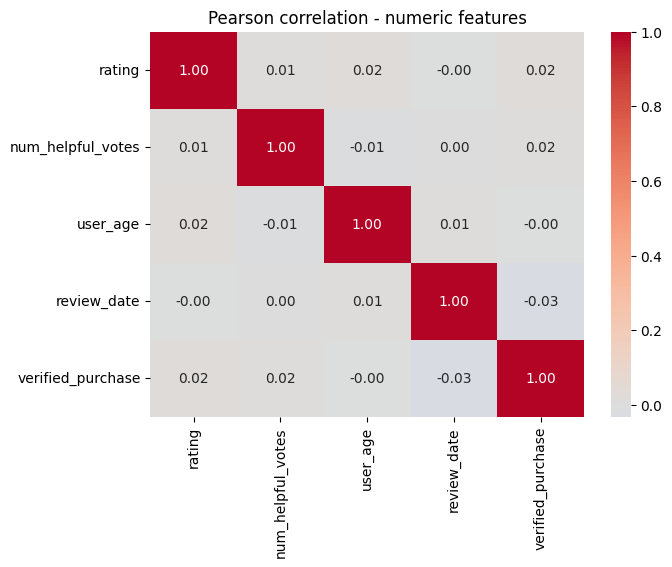

Correlation ratio (eta) with rating:
app_version        0.912
app_name           0.116
review_language    0.100
user_country       0.095
app_category       0.082
user_gender        0.038
device_type        0.037
dtype: float64


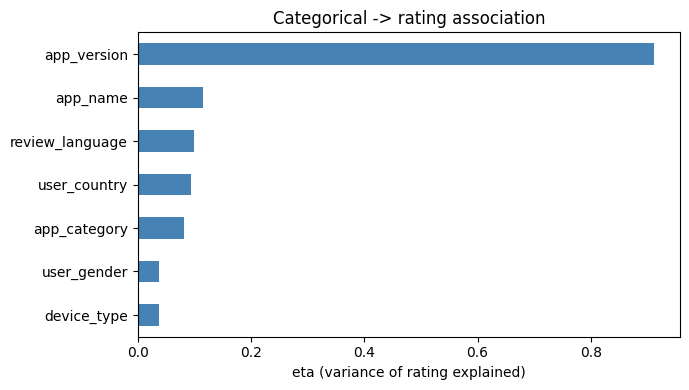

In [7]:

numeric_cols = ['rating', 'num_helpful_votes', 'user_age', 'review_date', 'verified_purchase']
pearson = df_enc[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(pearson, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Pearson correlation - numeric features')
plt.show()


def correlation_ratio(categories, values):
    categories = np.asarray(categories)
    values = np.asarray(values, dtype=float)
    y_mean = values.mean()
    ss_between = sum(
        (values[categories == c].size) * (values[categories == c].mean() - y_mean) ** 2
        for c in np.unique(categories)
    )
    ss_total = ((values - y_mean) ** 2).sum()
    return np.sqrt(ss_between / ss_total) if ss_total else 0.0

cat_features = ['app_name', 'app_category', 'review_language',
                'device_type', 'user_country', 'user_gender', 'app_version']
eta = {c: correlation_ratio(df_clean[c], df_clean['rating']) for c in cat_features}
eta_series = pd.Series(eta).sort_values(ascending=False)

print('Correlation ratio (eta) with rating:')
print(eta_series.round(3))


plt.figure(figsize=(7, 4))
eta_series.plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.xlabel('eta (variance of rating explained)')
plt.title('Categorical -> rating association')
plt.tight_layout()
plt.show()

## Target and feature insights

Before preprocessing, we need to understand:
1. How is `rating` distributed? (balanced? skewed?)
2. Which apps / categories show the strongest differences?
3. Does `review_text` length carry signal? (likely the strongest predictor we're ignoring so far)
4. Any time drift or duplicates that would bias training?

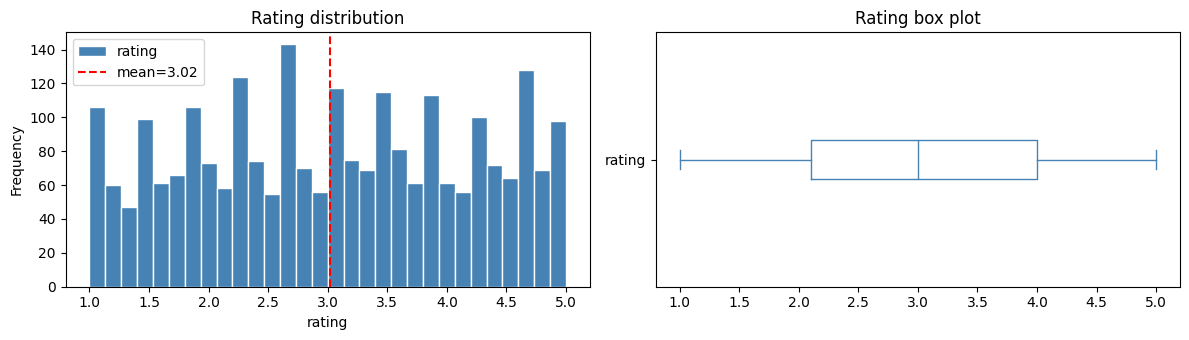

count    2477.00
mean        3.02
std         1.15
min         1.00
25%         2.10
50%         3.00
75%         4.00
max         5.00
Name: rating, dtype: float64


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df_clean['rating'].plot(kind='hist', bins=30, ax=ax[0], color='steelblue', edgecolor='white')
ax[0].axvline(df_clean['rating'].mean(), color='red', linestyle='--', label=f"mean={df_clean['rating'].mean():.2f}")
ax[0].set_title('Rating distribution')
ax[0].set_xlabel('rating')
ax[0].legend()
df_clean['rating'].plot(kind='box', ax=ax[1], vert=False, color='steelblue')
ax[1].set_title('Rating box plot')
plt.tight_layout()
plt.show()

print(df_clean['rating'].describe().round(2))

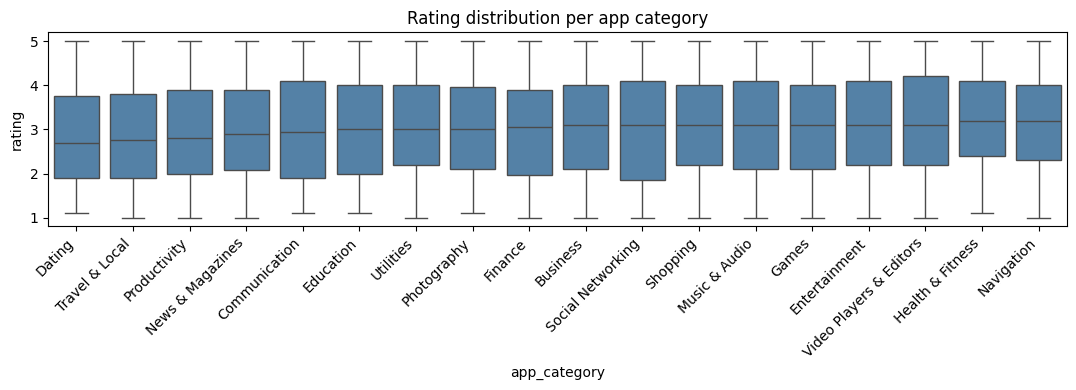

Top 5 apps by mean rating (min 20 reviews):
              mean  count
app_name                 
Snapchat      3.31     49
OneDrive      3.29     74
Khan Academy  3.27     52
Uber          3.21     63
Grammarly     3.20     66

Bottom 5 apps by mean rating (min 20 reviews):
                 mean  count
app_name                    
Tinder           2.71     61
Adobe Photoshop  2.79     68
Twitter          2.80     59
Booking.com      2.82     61
Waze             2.86     64


In [9]:
# --- Rating by category + top/bottom apps ---
plt.figure(figsize=(11, 4))
order = df_clean.groupby('app_category')['rating'].median().sort_values().index
sns.boxplot(data=df_clean, x='app_category', y='rating', order=order, color='steelblue')
plt.xticks(rotation=45, ha='right')
plt.title('Rating distribution per app category')
plt.tight_layout()
plt.show()

app_stats = (df_clean.groupby('app_name')['rating']
             .agg(['mean', 'count'])
             .query('count >= 20')
             .round(2))
print('Top 5 apps by mean rating (min 20 reviews):')
print(app_stats.sort_values('mean', ascending=False).head(5))
print('\nBottom 5 apps by mean rating (min 20 reviews):')
print(app_stats.sort_values('mean').head(5))

Mean rating by review length bucket:
               mean  count
review_length             
0-50           2.99    666
51-100         3.03   1624
101-200        3.08    187


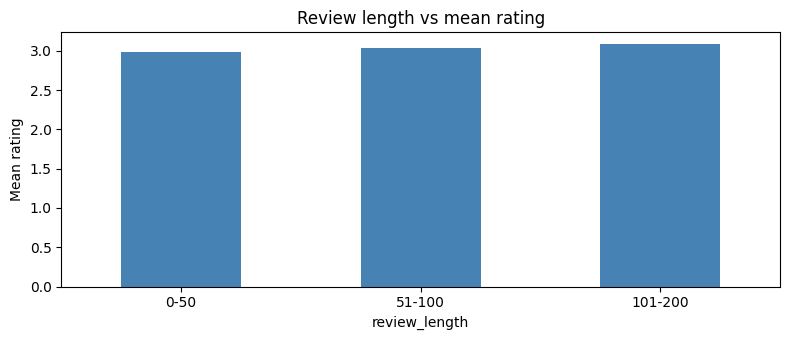

In [ ]:
# Review text: does length correlate with rating
df_clean['review_length'] = df_clean['review_text'].str.len()

length_bucket = pd.cut(df_clean['review_length'],
                       bins=[-1, 50, 100, 200, 500, 10000],
                       labels=['0-50', '51-100', '101-200', '201-500', '500+'])
bucket_stats = df_clean.groupby(length_bucket, observed=True)['rating'].agg(['mean', 'count']).round(2)
print('Mean rating by review length bucket:')
print(bucket_stats)

plt.figure(figsize=(8, 3.5))
bucket_stats['mean'].plot(kind='bar', color='steelblue')
plt.ylabel('Mean rating')
plt.title('Review length vs mean rating')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

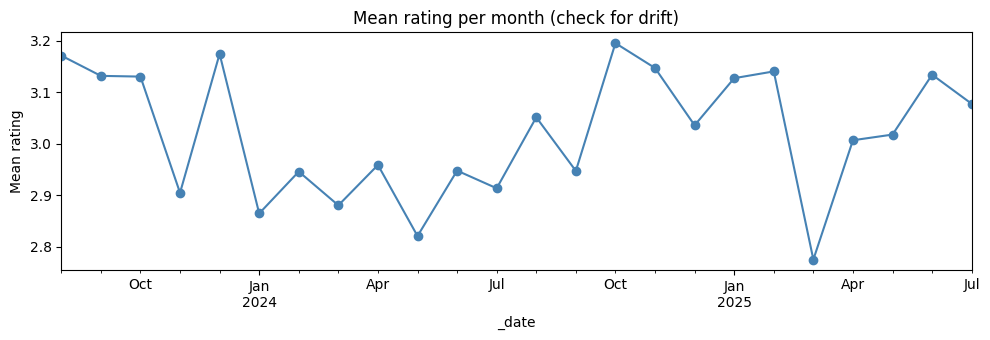

Duplicate (user_id, app_name) rows : 0
Date range                         : 2023-08-01 -> 2025-07-31

Numeric column ranges (outlier check):
       user_age  num_helpful_votes  review_length
count    2477.0             2477.0         2477.0
mean       44.2              615.5           57.5
std        18.4              364.1           24.9
min        13.0                0.0            0.0
25%        28.0              286.0           50.0
50%        44.0              618.0           53.0
75%        60.0              920.0           55.0
max        75.0             1249.0          179.0


In [ ]:
# Time drift + data integrity checks 
df_clean['_date'] = pd.to_datetime(df_clean['review_date'])
monthly = df_clean.groupby(df_clean['_date'].dt.to_period('M'))['rating'].agg(['mean', 'count'])

fig, ax = plt.subplots(figsize=(10, 3.5))
monthly['mean'].plot(ax=ax, color='steelblue', marker='o')
ax.set_title('Mean rating per month (check for drift)')
ax.set_ylabel('Mean rating')
plt.tight_layout()
plt.show()

dup_pairs = df_clean.duplicated(subset=['user_id', 'app_name']).sum()
print(f'Duplicate (user_id, app_name) rows : {dup_pairs}')
print(f'Date range                         : {df_clean["_date"].min().date()} -> {df_clean["_date"].max().date()}')
print('\nNumeric column ranges (outlier check):')
print(df_clean[['user_age', 'num_helpful_votes', 'review_length']].describe().round(1))

df_clean = df_clean.drop(columns=['_date', 'review_length'])

## EDA takeaways

These findings directly shape the preprocessing and modeling decisions in `02_preprocessing.ipynb`:

- **Target `rating`** — inspect shape (uniform / skewed) and mean. If skewed, consider `log1p` or target binning later.
- **Demographic features (`user_age`, `user_gender`, `user_country`)** — correlation ratio (η) and Pearson are low. Likely weak predictors, candidates for dropping or aggressive regularization.
- **Review length** — clear ordered effect on mean rating = **signal we must engineer as a feature** (`review_length`, `word_count`), even before full NLP.
- **App identity (`app_name`, `app_category`)** — largest η values. High cardinality of `app_name` means it needs **ordinal / target encoding**, not one-hot (would explode dimensions).
- **Time** — check monthly mean plot; if flat, random train/test split is fine. If drifting, use time-based split.
- **Data integrity** — duplicate (user, app) pairs and outlier ranges flagged for decisions in preprocessing.

**Next:** build a sklearn `ColumnTransformer` pipeline that applies imputation + encoding + scaling consistently, with no leakage between train and test.